# A Few Interpretation Analysis

In [1]:
from matplotlib import pyplot as plt
from src.utils.config import load_config
import pickle
from src.data.dataset import Dataset, decode
from src.model.transformer import Transformer
from src.training.evaluator import Evaluator
from src.utils.transformer_analysis import *
# from src.data.dyck_generator import generate_dyck_data
import torch
import torch.nn as nn
import sys
import os
import numpy as np
import random
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

# Set random seeds:
seed = 42   # choose your random seed
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)  # For CUDA reproducibility
np.random.seed(seed)
random.seed(seed)
os.environ["PYTHONHASHSEED"] = str(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## 1. Load the model and dataset

In [2]:
#=================================
# load your model here by specifying the training timestamp 
#---------------------------------
sesh = 'n13_head1'  # change this to your session name
                     # preloaded ones: n13_head1, n13_head2, n13_head3, n13_head4, decoder, n13_head1_seed0

In [3]:
#=================================
# load config
config_path = f'cache/{sesh}/config'
config = load_config(config_path)

# load cached dataset, generate if not exists
batch_size = config['training']['batch_size']
n = config['data']['n']      
data_path = config['data']['data_path']
try:
    with open(data_path, 'rb') as f:
        data = pickle.load(f)
    print(f"Data loaded successfully from {data_path}.")
except FileNotFoundError:
    print(f"Data file not found.")
    # generate_dyck_data(n, data_path)
    with open(data_path, 'rb') as f:
        data = pickle.load(f)
    print(f"Data generated and loaded successfully.")
except Exception as e:
    raise Exception(f"Error loading saved data: {e}.")

# load the best trained model from the designated session
model_args = config['model']
if model_args['architecture'] == "decoder_only":
    model_args['max_len'] = (n*2+2)*2 # including BOS and EOS tokens from both input and target sequences
    max_new_tokens = 2*n + 2  # BOS, steps, EOS
else:
    model_args['max_len'] = n*2 + 1  # +1 for BOS token
    # max_new_tokens = model_args['max_len'] - 1  # Exclude BOS token, so -1
    max_new_tokens = n*2  # generate just the steps given BOS in the decoder

# load the datset
if model_args['architecture'] != "decoder_only":
    dataset = Dataset(data,seed=seed,batch_size=batch_size)
else:
    dataset = Dataset(data,seed=seed,batch_size=batch_size,decoder_only=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
criterion = nn.CrossEntropyLoss()      
model = Transformer(**model_args)
model_path = f'cache/{sesh}/best_model.pth'
model.load_state_dict(torch.load(model_path,map_location=torch.device('cpu')))
model.to(device)
model.eval()
print(f"Best model loaded from {sesh}.")

# Evaluate the model on the validation dataset to see how it performs
evaluator = Evaluator(model, dataset.eval_dataloader, criterion, device)
# eval_loss_epoch, eval_accuracy_epoch = evaluator.evaluate(max_new_tokens)
# print(f"validation data: loss = {eval_loss_epoch:.4f}, accuracy = {eval_accuracy_epoch:.8f}")

# load analysis examples from the validation dataset
examples = {
    'inputs': dataset.eval_dataloader.dataset.tensors[0].to(device),  # First 5 inputs
    'targets': dataset.eval_dataloader.dataset.tensors[1].to(device)   # First 5 targets
}

Data loaded successfully from data/dyck_data_13.pkl.
Best model loaded from n13_head1.


## 2. Example Usage

### Example 2a. Visualize encoder, decoder self-attention, cross-attention, and Dyck Paths for one example

Input: bos 1 1 1 0 1 0 1 1 1 0 1 1 0 1 0 1 0 1 1 0 0 0 0 0 0 0
Target: bos 1 0 1 1 1 1 0 0 0 0 1 1 0 0 1 0 1 1 1 0 0 0 1 0 1 0


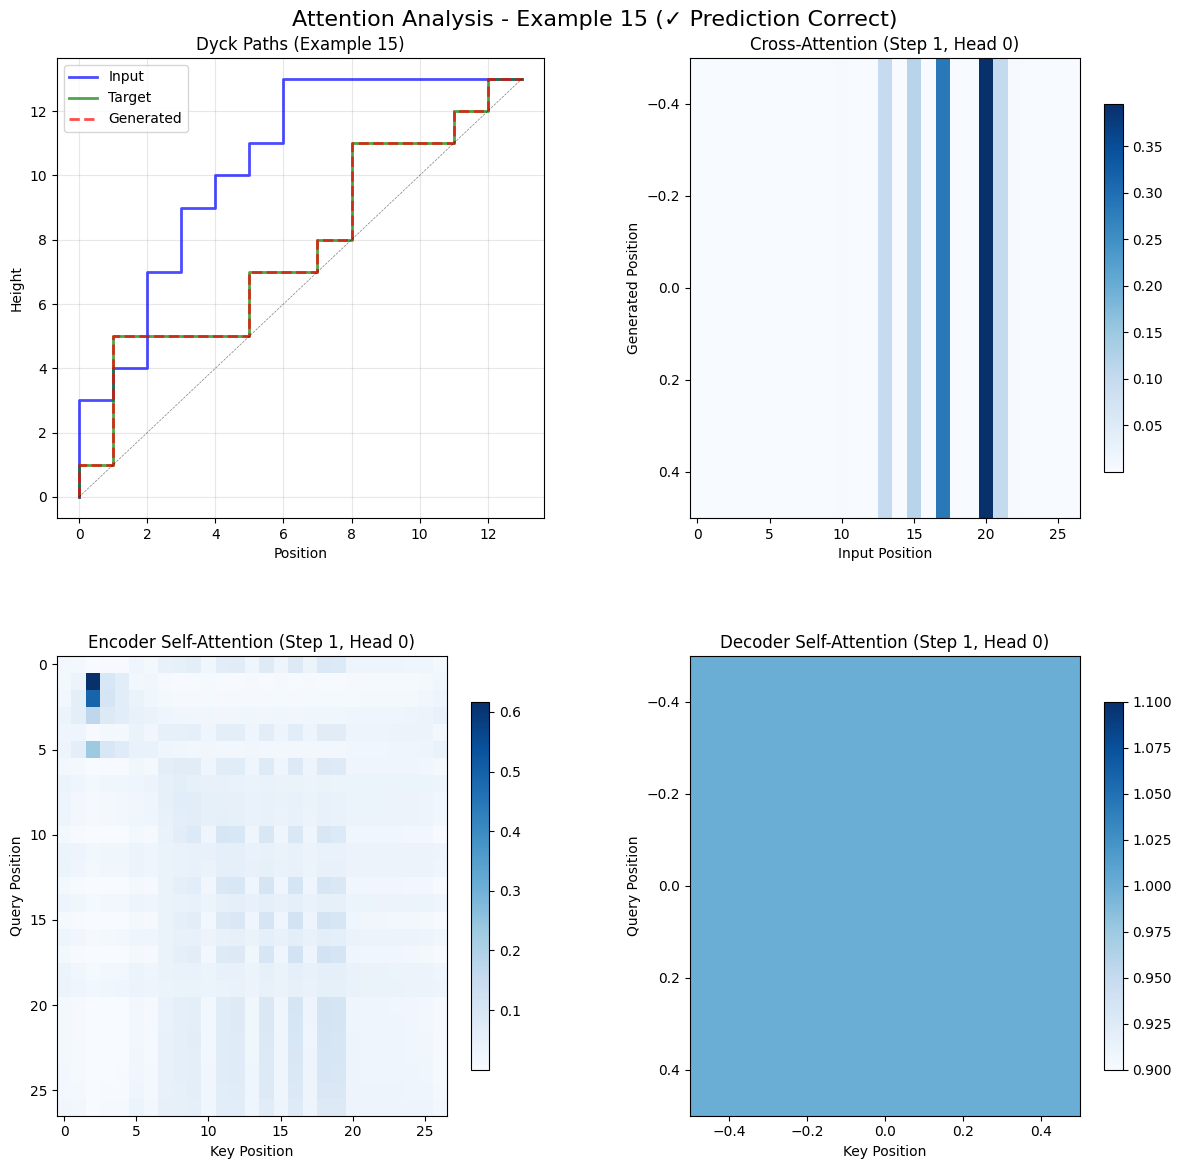

In [4]:
# Example: Analyze data example #15
# this if for all attention heads numbered 0 at step 21 (the 22th token generated in the sequence)
#=================
# choose the example, step of generation and attention heads to analyze
ex_idx = 15  # the index of the first example to analyze
encoder_att_head = 0  # which encoder self-attention head to analyze. 0 means the first head
decoder_att_head = 0  # which decoder self-attention head to analyze. 0 means the first head
cross_att_head = 0  # which cross-attention head to analyze. 0 means the first head
step =  0 # which token is being generated in the sequence when analyzing cross-attention. 0 means the first token after BOS.
# some plotting parameters
figsize = (12,12)  # figure size for visualization
cmap = 'Blues'  # colormap for visualization, e.g. 'Blues', 'inferno', 'viridis'
#=================
# outputs = analyze_cross_attention(model, examples, start_idx=start_idx, step=step, att_head=att_head, num_examples=num_examples)
print(f"Input: {decode(examples['inputs'][ex_idx], dataset.dictionary)}")
print(f"Target: {decode(examples['targets'][ex_idx], dataset.dictionary)}")

outputs = attention_example(model, examples, dataset, ex_idx=ex_idx, step=step, encoder_att_head=encoder_att_head, decoder_att_head=decoder_att_head, cross_att_head=cross_att_head, figsize=figsize, cmap=cmap)

### Example 2b. Visualize Cross Attentions for a Batch of Examples

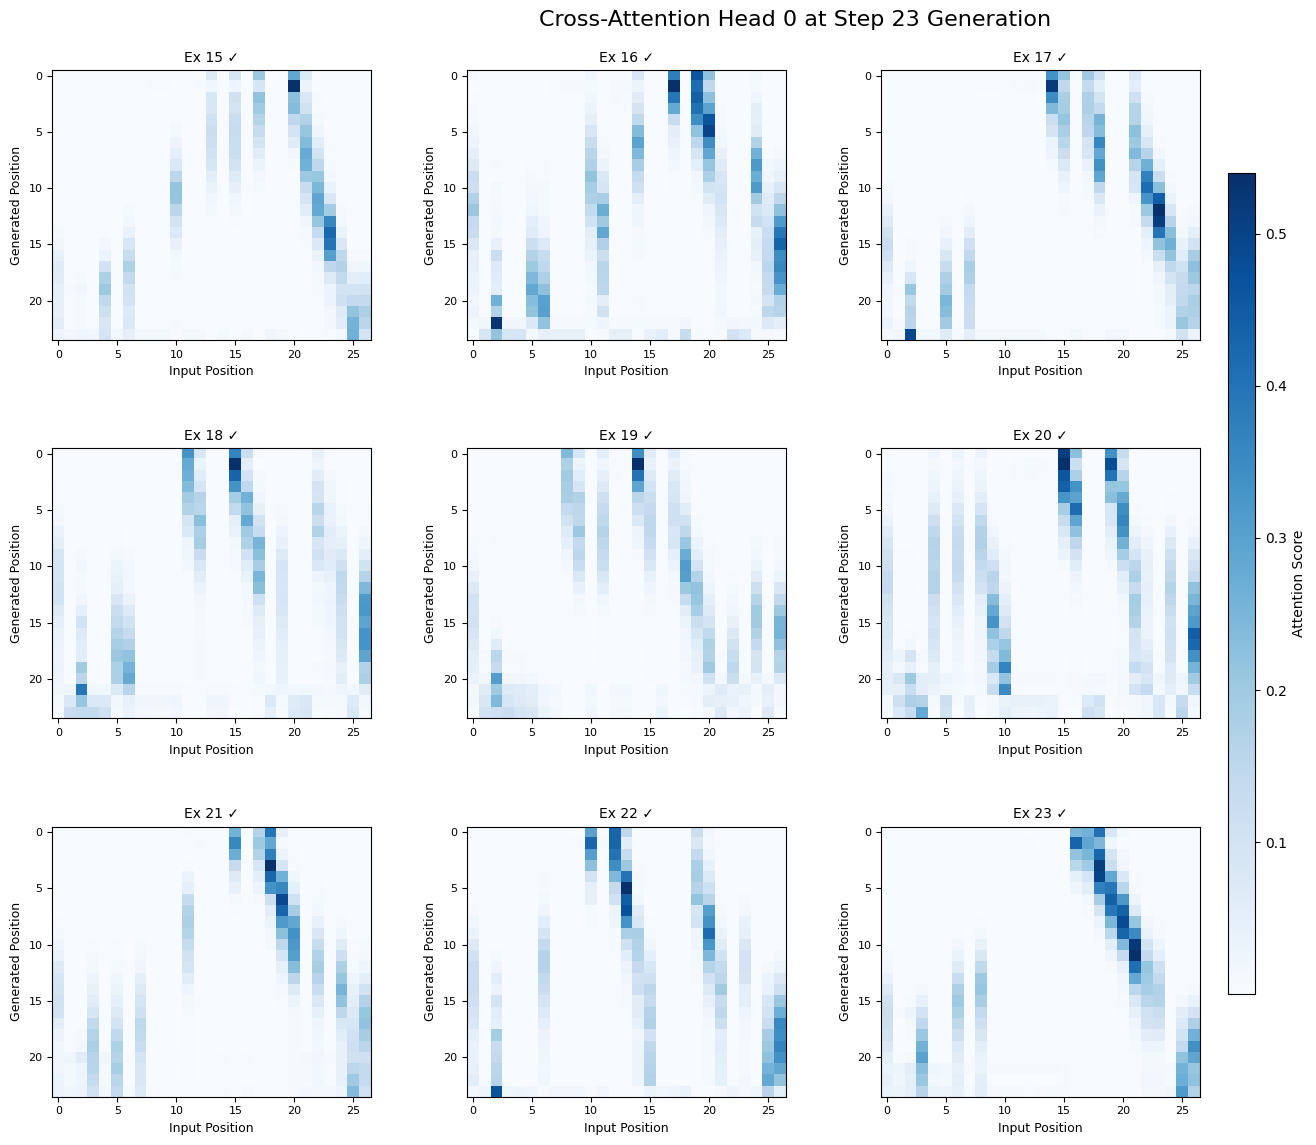

In [5]:
# Example: Analyze 9 examples starting from example #15
# all for attention head 0 at step 21 (the 22th token generated in the sequence)
# The ✓ and ✗ in the title indicate whether the Dyck path is predicted correctly or not
#=================
# choose the examples, step of generation and attention heads to analyze
start_idx = 15  # the index of the first example to analyze
num_examples = 9  # Number of examples to show
att_head = 0    # attention head to visualize
step = 23  # which token is being generated in the sequence when analyzing cross-attention. 0 means the first token after BOS.
# some plotting parameters
figsize = (16, 12)  # figure size for visualization
cmap = 'Blues'  # colormap for visualization, e.g. 'Blues', 'inferno', 'viridis'
#=================
outputs = analyze_cross_attention(model, examples, start_idx=start_idx, step=step, att_head=att_head, num_examples=num_examples, figsize=figsize, cmap=cmap)

### Example 2c. Visualize encoder self attention for a batch of examples

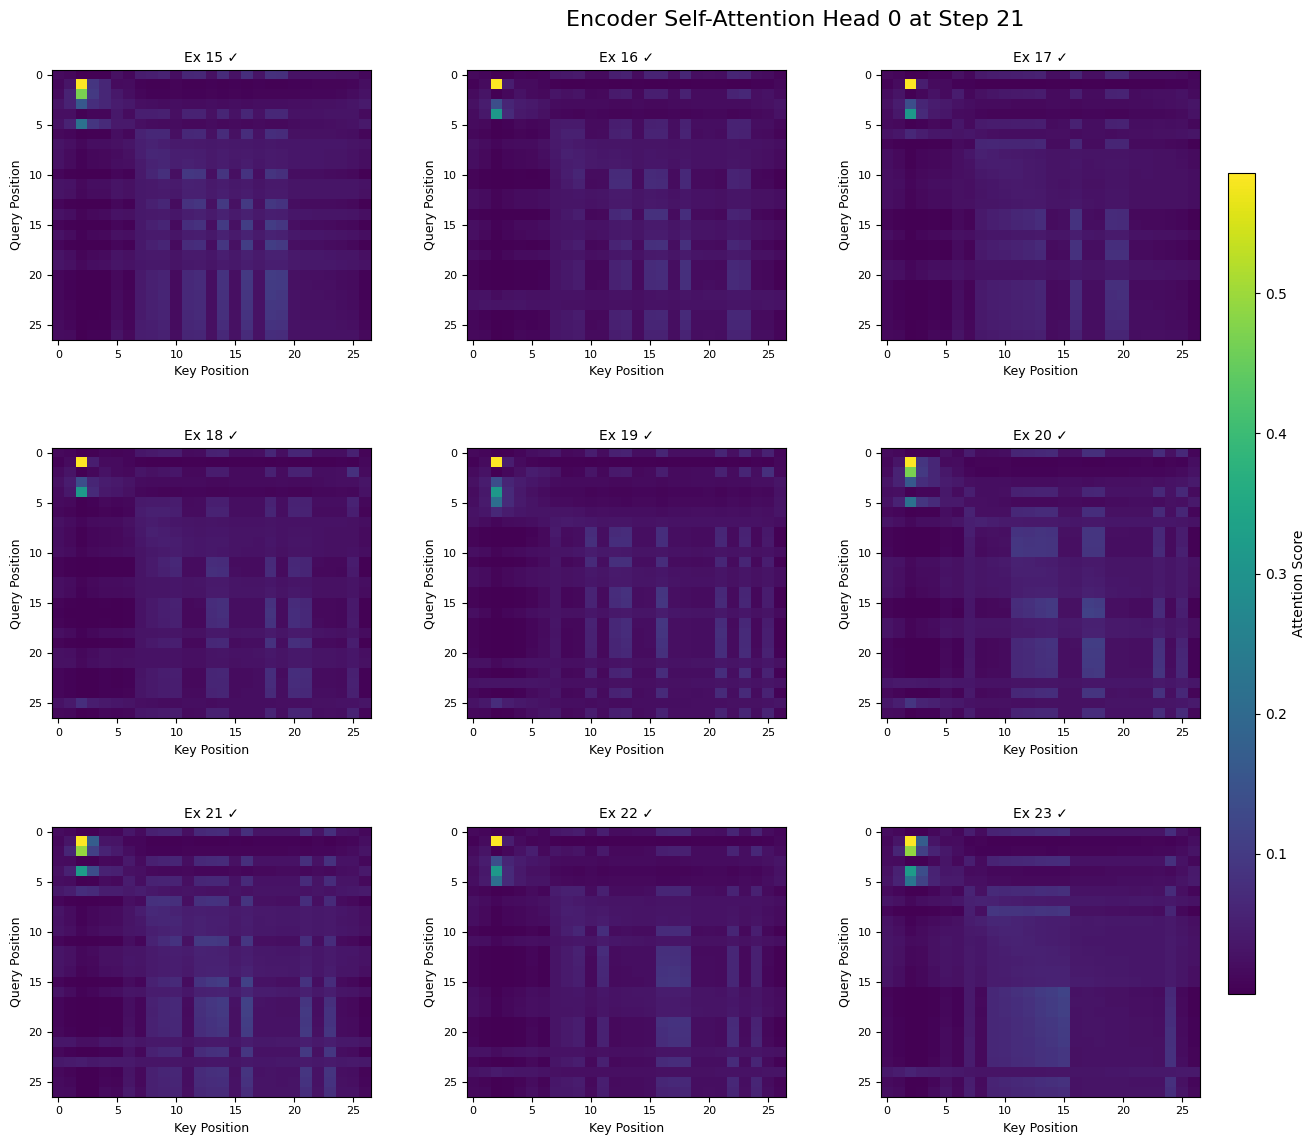

In [6]:
# Example: Analyze 9 examples starting from example #15
# all for attention head 0 at step 21 (the 22th token generated in the sequence)
# The ✓ and ✗ in the title indicate whether the Dyck path is predicted correctly or not
#=================
# choose the examples, step of generation and attention heads to analyze
start_idx = 15  # the index of the first example to analyze
num_examples = 9  # Number of examples to show
att_head = 0    # attention head to visualize
step = 21  # which token is being generated in the sequence when analyzing attention
# some plotting parameters
figsize = (16, 12)  # figure size for visualization
cmap = 'viridis'  # colormap for visualization, e.g. 'Blues', 'inferno', 'viridis'
#=================
outputs = analyze_encoder_attention(model, examples, start_idx=start_idx, step=step, att_head=att_head, num_examples=num_examples, figsize=figsize, cmap=cmap)

### Example 2d. Visualize decoder self attention for a batch of examples

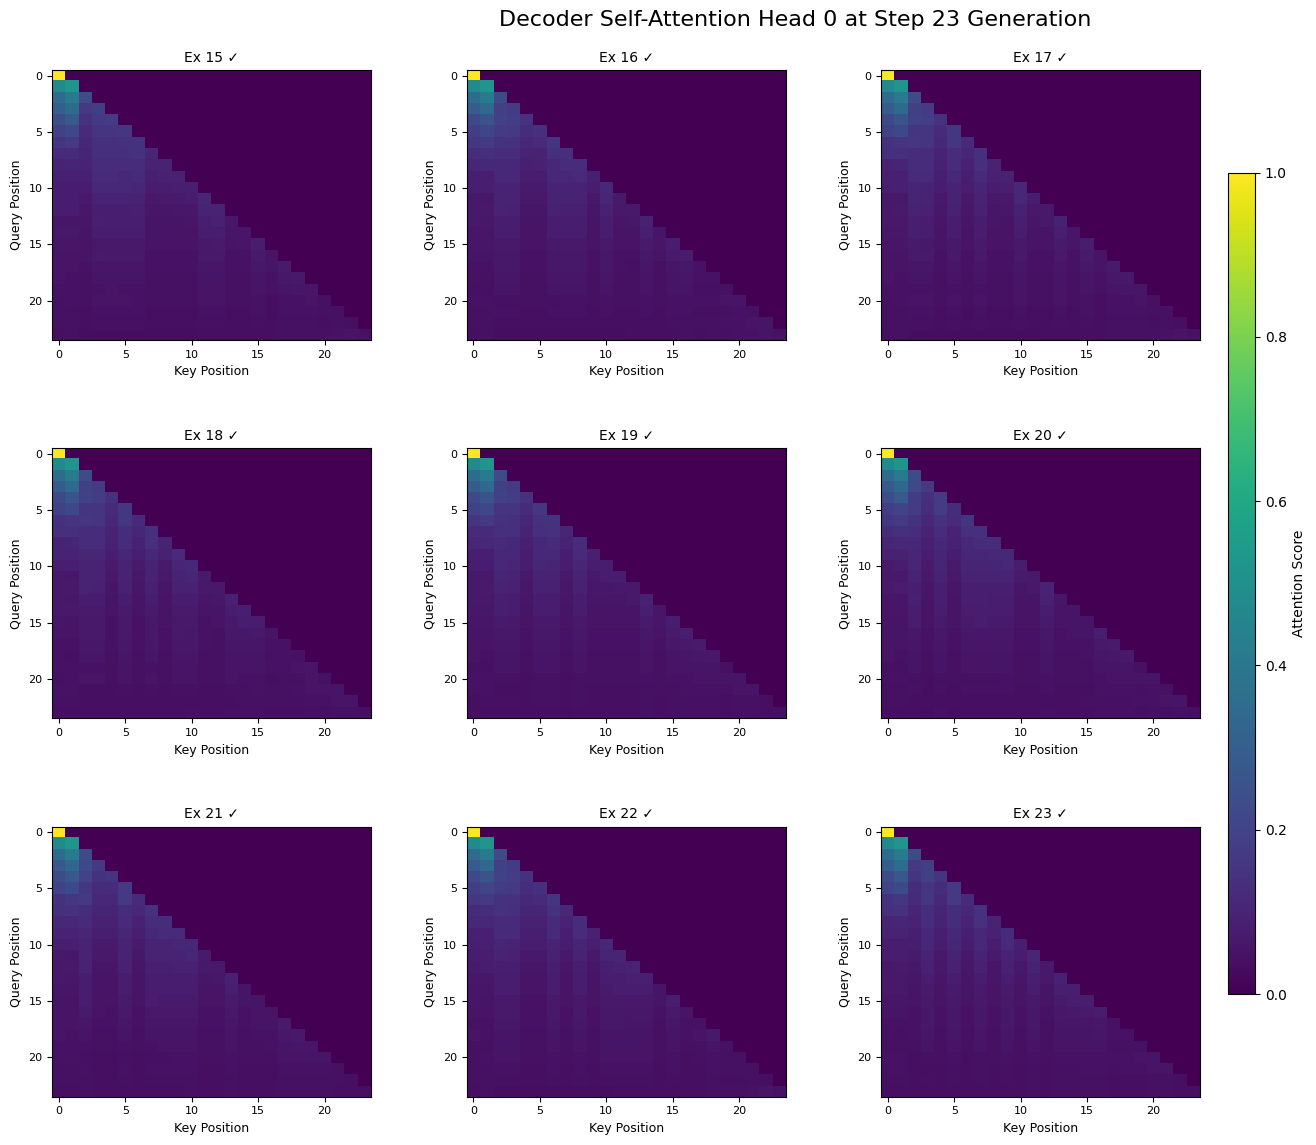

In [7]:
# Example: Analyze 9 examples starting from example #15
# all for attention head 0 at step 21 (the 22th token generated in the sequence)
# The ✓ and ✗ in the title indicate whether the Dyck path is predicted correctly or not
#=================
# choose the examples, step of generation and attention heads to analyze
start_idx = 15  # the index of the first example to analyze
num_examples = 9  # Number of examples to show
att_head = 0    # attention head to visualize
step = 23  # which token is being generated in the sequence when analyzing attention
# some plotting parameters
figsize = (16, 12)  # figure size for visualization
cmap = 'viridis'  # colormap for visualization, e.g. 'Blues', 'inferno', 'viridis'
#=================
outputs = analyze_decoder_attention(model, examples, start_idx=start_idx, step=step, att_head=att_head, num_examples=num_examples, figsize=figsize, cmap=cmap)

### Example 2e. Visualize cross attention across all the steps

Input: bos 1 0 1 1 0 1 0 1 1 1 1 1 1 0 0 1 0 0 1 1 0 0 0 0 0 0
Target: bos 1 1 1 0 1 0 1 0 0 1 0 0 1 0 1 0 1 1 1 0 0 0 1 1 0 0


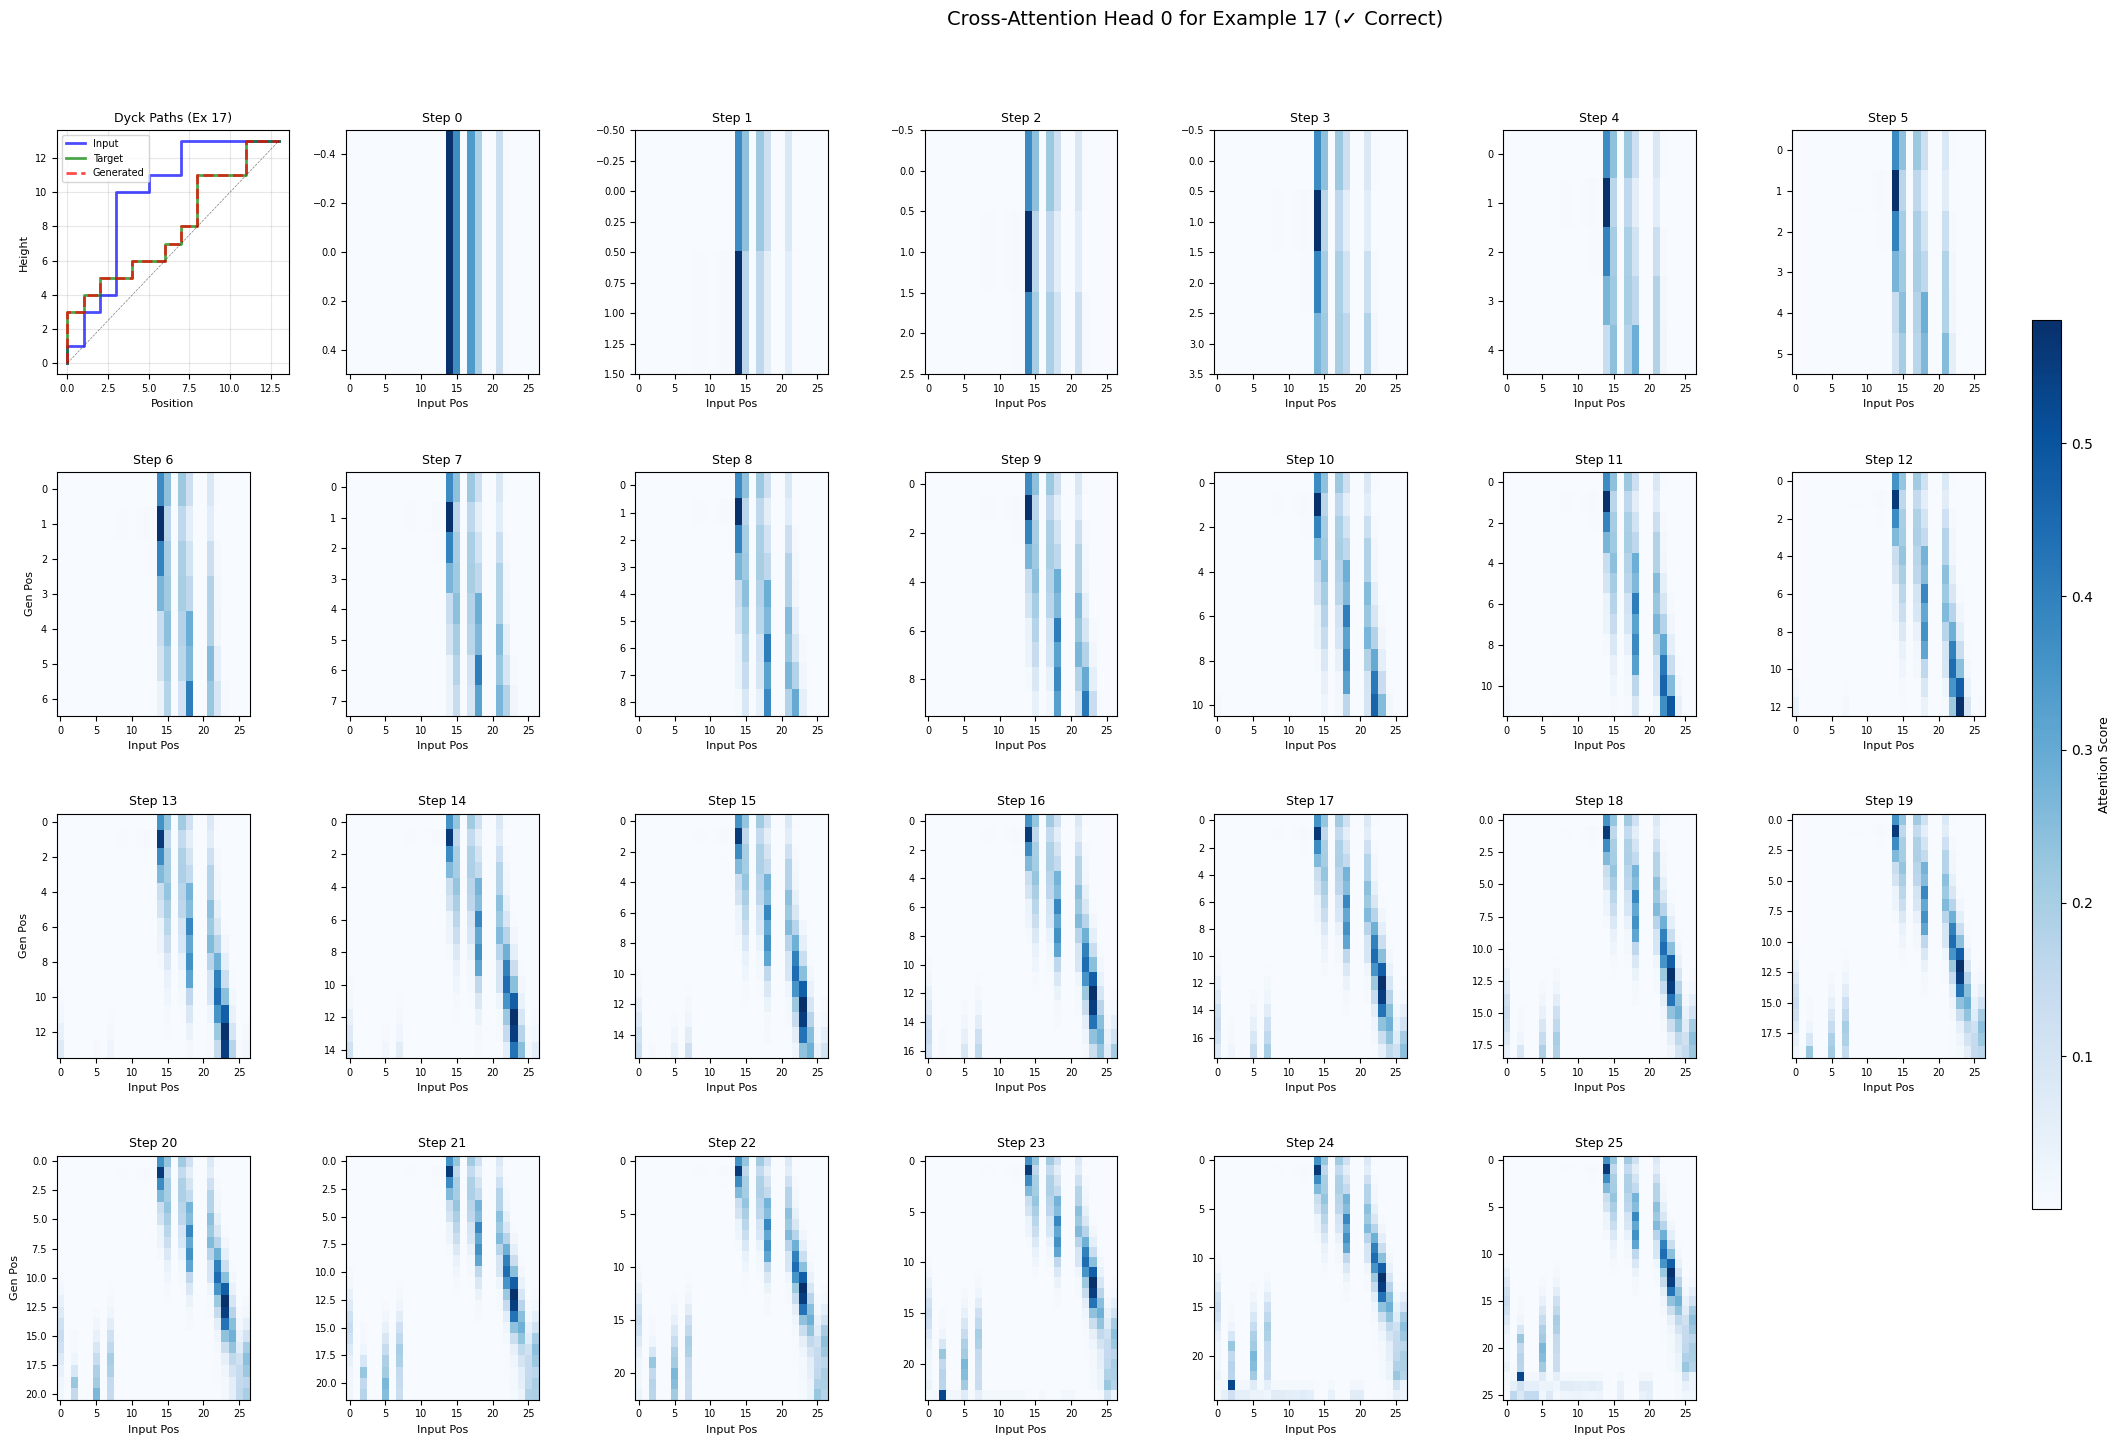

In [8]:
# Example: Analyze example #15
# this generates attention maps for all steps in one sequence generation
#=================
# choose the example and attention heads to analyze
ex_idx = 17 # the index of the first example to analyze
att_head = 0    # attention head to visualize
# some plotting parameters
figsize = (24,15)  # figure size for visualization
cmap = 'Blues'  # colormap for visualization, e.g. 'Blues', 'inferno', 'viridis'
#=================
print(f"Input: {decode(examples['inputs'][ex_idx], dataset.dictionary)}")
print(f"Target: {decode(examples['targets'][ex_idx], dataset.dictionary)}")

outputs = analyze_cross_attention_all_steps(model, examples, dataset, ex_idx=ex_idx, att_head=att_head, figsize=figsize, cmap=cmap)

### Example 2f. Level vs. Cross-Attention Comparison

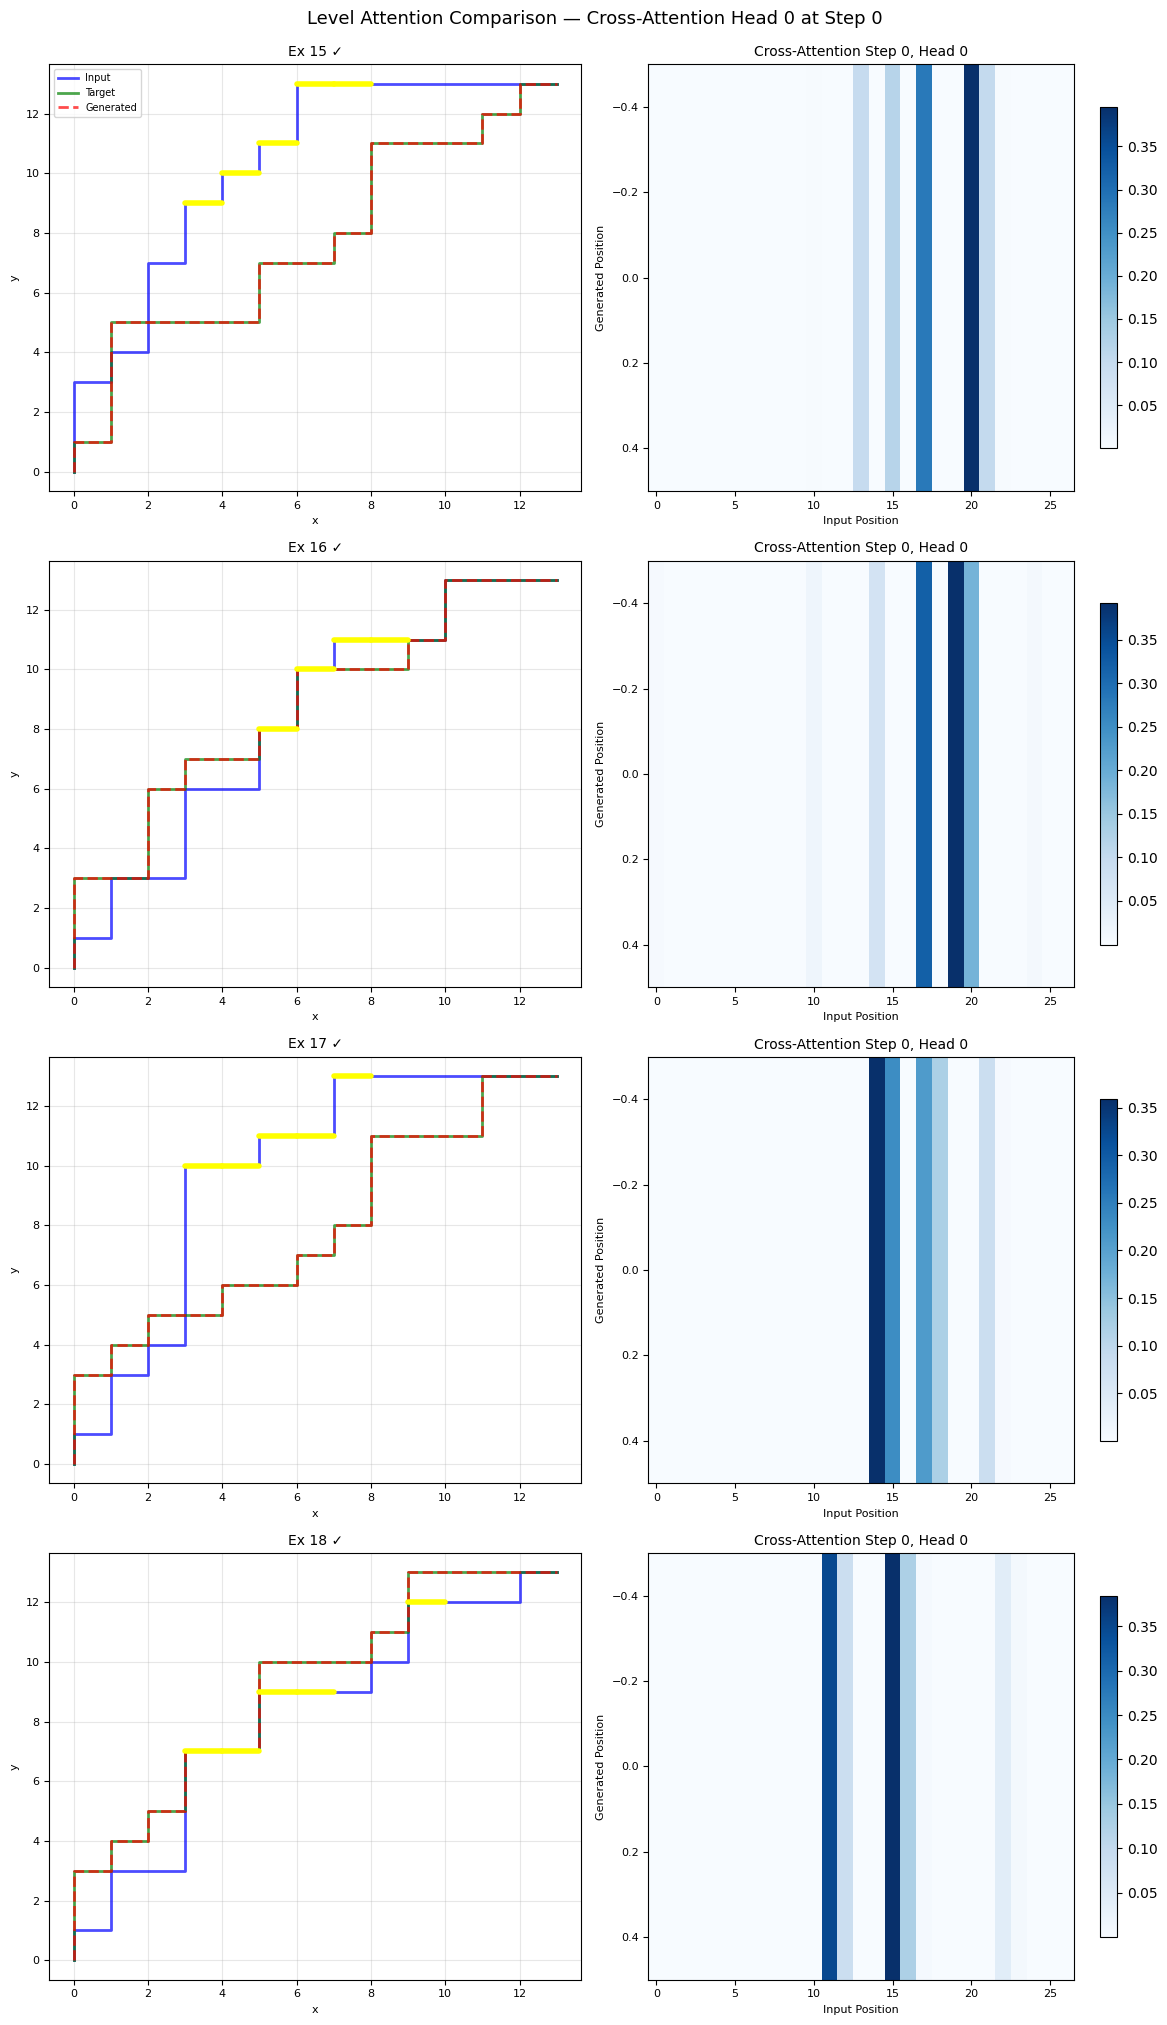

In [9]:
# For 4 consecutive examples, plot side-by-side:
#   Left  — Input / Target / Generated Dyck paths; yellow dots mark input positions
#            with above-mean cross-attention weight at step 0 (the first generated token)
#   Right — Cross-attention heatmap at step 0 (bimodal: near-zero vs. high weights)
#=================
start_idx = 15   # first of the 4 consecutive examples
att_head  = 0    # which cross-attention head to inspect
figsize   = (12, 20)
cmap      = 'Blues'
#=================
level_attention_comparison(
    model, examples, dataset,
    start_idx=start_idx,
    att_head=att_head,
    figsize=figsize,
    cmap=cmap
)

### Example 2g. PCA of encoder and decoder embeddings

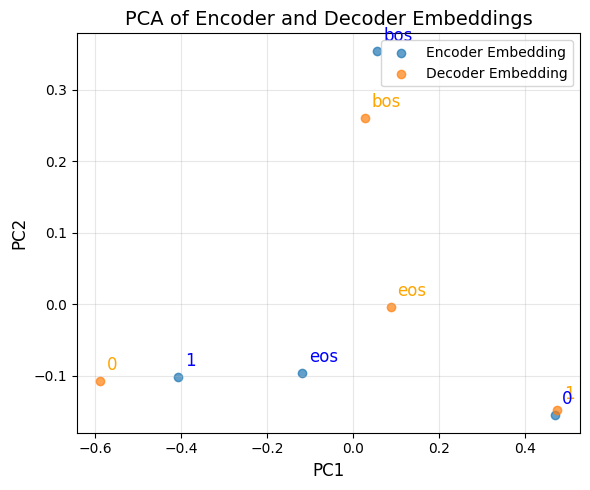

In [10]:
# run a PCA on the encoder and decoder token embeddings
# note: it is likely that the encoder and decoder used different pca projections
outputs = analyze_embeddings_pca(model, dataset, figsize=(6, 5), alpha=0.7, fontsize=12)

## Visualize positional Embeddings

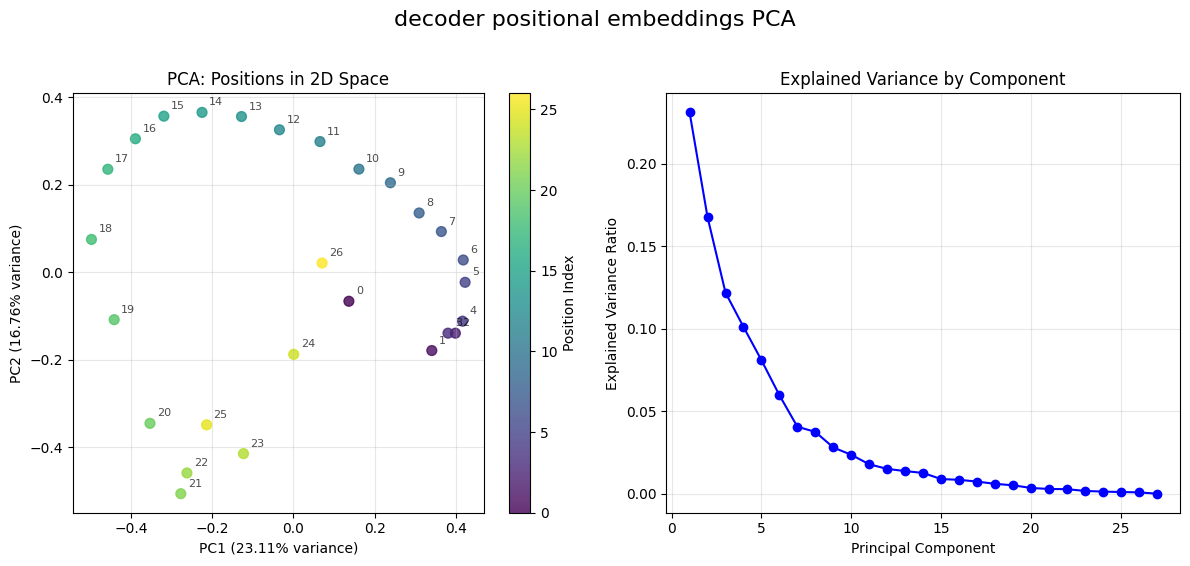

{'pos_pca_full': array([[ 1.36351898e-01, -6.65679723e-02,  5.80913089e-02,
          9.18661281e-02, -2.66970918e-02, -1.13468140e-01,
          9.69232246e-03, -3.52970995e-02, -2.13165842e-02,
          2.70942273e-03,  9.88557041e-02, -8.36594030e-03,
          7.10454211e-02, -5.24179339e-02,  1.48252934e-01,
          1.16693214e-01,  1.37414664e-01, -1.10265285e-01,
         -1.50033971e-02,  2.21235696e-02, -1.89769026e-02,
         -6.02532877e-03, -4.36220551e-03,  9.42149106e-03,
          1.05160614e-03,  2.47000367e-03,  7.38023047e-08],
        [ 3.40400040e-01, -1.79195285e-01,  2.43132766e-02,
          5.67123294e-01, -3.16937894e-01, -3.40300292e-01,
         -2.30359107e-01, -1.90087974e-01,  2.83560678e-02,
         -5.97829930e-02, -4.57724705e-02, -4.17760620e-03,
         -3.33851799e-02,  4.79068048e-02, -4.91701290e-02,
          1.37678180e-02, -1.83973387e-02,  3.25755440e-02,
         -3.72339822e-02,  1.43351508e-02,  1.73560437e-03,
         -1.42905861e-0

In [11]:
analyze_positional_embeddings_pca(model, module = "decoder", n_components=28, figsize = (12,5.5), plot_labels = True)

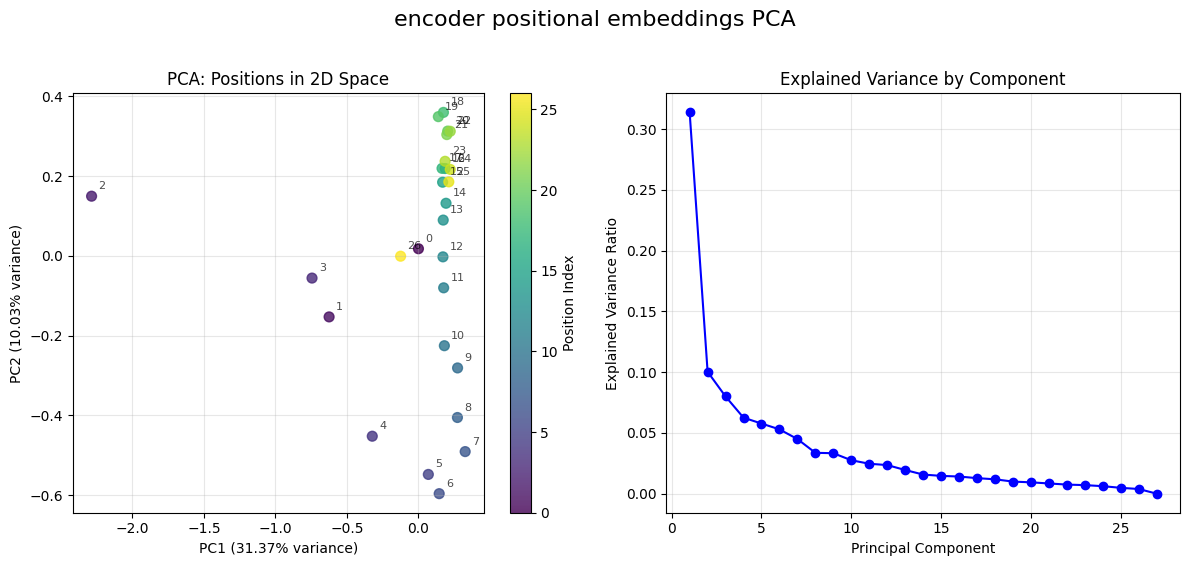

{'pos_pca_full': array([[ 1.38423219e-03,  1.79419070e-02,  2.68676784e-02,
          4.42179553e-02, -3.22251096e-02, -2.54816115e-02,
         -2.21129116e-02,  2.22598650e-02,  1.37387998e-02,
         -4.00713868e-02, -2.31629983e-02, -8.16197023e-02,
          5.75508662e-02, -9.06045958e-02, -1.13840222e-01,
          8.05494487e-02, -6.78199083e-02, -6.59397840e-02,
         -2.15413701e-02, -1.84243232e-01,  1.06575988e-01,
          2.55555779e-01,  1.03882447e-01, -1.40215501e-01,
         -1.33680692e-02,  2.34824605e-02,  1.22626957e-07],
        [-6.23793900e-01, -1.52995989e-01,  1.03089982e-03,
          8.53157341e-02,  1.16434544e-01, -4.08488214e-01,
          1.42419413e-01, -1.75693724e-02, -4.44676250e-01,
          4.58438277e-01, -5.12908325e-02,  6.59089908e-02,
          1.14114039e-01,  1.03248321e-01,  2.73454934e-03,
         -9.79531258e-02, -4.23928648e-02, -5.27828336e-02,
          6.44507306e-03,  2.92827841e-02,  8.92598275e-03,
          1.84498392e-0

In [12]:
analyze_positional_embeddings_pca(model, module = "encoder", n_components=28, figsize = (12,5.5), plot_labels = True)

## Ablation Studies: testing the effect of zeroing out the attention token 1s on accuracy

Analyzing the effect of zeroing out cross attention to token 1


c:\Users\Xiaoyu Huang\Documents\DyckTransformer\src\utils\transformer_analysis.py:1106: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  token_id = torch.tensor(token_id)


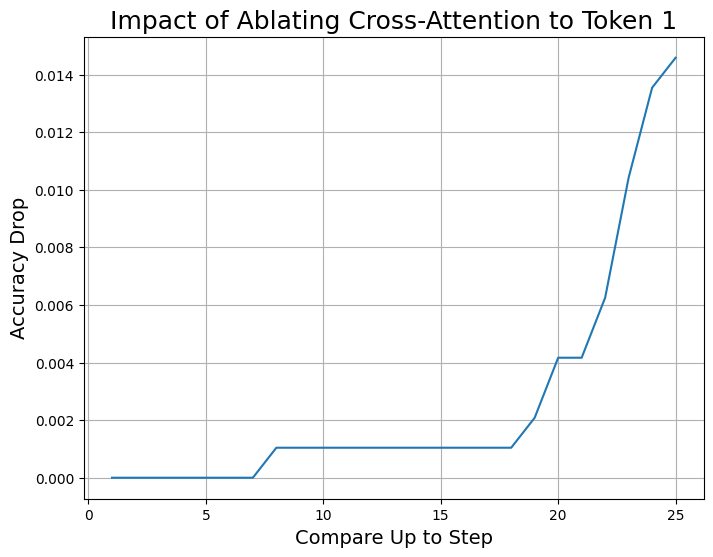

In [13]:
token_to_ablate = torch.tensor(3)  # Change this to ablate different tokens. 3 corresponds to the token for step "1" in the generated sequence.
n_batches = 30 # Number of batches to evaluate on. Each batch ahs 32 examples.
eval_steps = list(range(1,26))  # Evaluate accuracies at these generation steps

print(f"Analyzing the effect of zeroing out cross attention to token {decode([token_to_ablate], dataset.dictionary)}")
normal_accs, normal_loss = evaluator.evaluate_by_steps(max_new_tokens, eval_steps = eval_steps, n_batches=n_batches)
ablated_accuracies, ablated_avg_loss = zero_cross_attention_to_token(model, dataset, criterion, token_to_ablate, device, n_batches = n_batches, eval_steps = eval_steps)

acc_diffs = {}
for step in eval_steps:
    acc_diffs[step] = normal_accs[step] - ablated_accuracies[step]
# fix a fig size
plt.figure(figsize=(8, 6))
plt.plot(acc_diffs.keys(), acc_diffs.values(),)
plt.xlabel('Compare Up to Step', fontsize=14)
plt.ylabel('Accuracy Drop', fontsize=14)
plt.title(f'Impact of Ablating Cross-Attention to Token {decode([token_to_ablate], dataset.dictionary)}', fontsize=18)
plt.grid(True)

## Probing: how much information about levels do hidden states contain?

In [14]:
# ignore some sklearn warnings so the output is cleaner
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics._classification import UndefinedMetricWarning

# Suppress specific sklearn warnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

===========Predict the level of each token based on the encoder hidden states===========
Probing Accuracy: 0.8381
===========Confusion Matrix===========


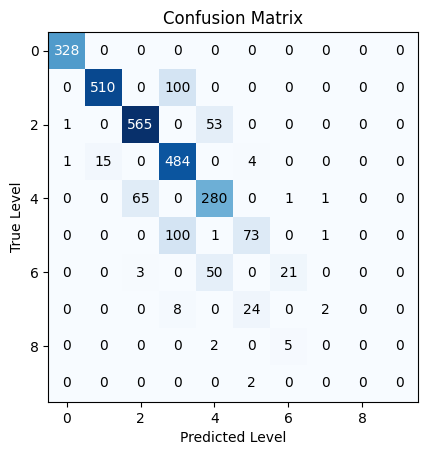

In [15]:
'''
Demonstrate probing the encoder hidden states to predict the level of each token
We extract the encoder hidden states and the level of each token in the input sequence
Then we train a simple logistic regression classifier to predict the level of each token based on the encoder hidden states
Finally, we evaluate the classifier on a held-out test set and report the accuracy

TODO: allow extracting states and levels separately
'''

# =================
# choose the number of examples for probing and the test size
n_examples = 500
test_size = 0.2
# =================

# levels = extract_levels(model, dataset.eval_dataloader, dataset.dictionary, device, max_samples=n_examples)
# states = extract_encoder_states(model, device, dataset.eval_dataloader, dataset.dictionary, max_samples=n_examples)
states, levels, positions = extract_encoder_states_and_levels(
        model, dataset.eval_dataloader, dataset.dictionary, device, max_samples=n_examples
    )
X = states.cpu().numpy()
y = levels.cpu().numpy()

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=seed)

# Train probe
probe = LogisticRegression(max_iter=1000, random_state=seed)
probe.fit(X_train, y_train)

# Evaluate
y_pred = probe.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)
print("===========Predict the level of each token based on the encoder hidden states===========")
print(f"Probing Accuracy: {accuracy:.4f}")

# plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
im = plt.imshow(cm, interpolation='nearest', cmap='Blues')
print('===========Confusion Matrix===========')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Level')
plt.ylabel('True Level')

# Add text annotations
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black")